In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch

In [5]:
df=pd.read_csv("Penguin Species Prediction Dataset.csv")

In [6]:
df.head()

,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,41.1,18.4,195.0,3886.0,Female
1,Gentoo,Biscoe,50.0,15.4,217.0,4303.0,Male
2,Gentoo,Biscoe,50.0,15.1,220.0,4954.0,Female
3,Chinstrap,Dream,48.7,19.0,196.0,3739.0,Male
4,Adelie,Dream,39.0,17.8,187.0,3607.0,Male


In [7]:
df.columns

Index(['species', 'island', 'culmen_length_mm', 'culmen_depth_mm',
       'flipper_length_mm', 'body_mass_g', 'sex'],
      dtype='object')

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            1000 non-null   object 
 1   island             1000 non-null   object 
 2   culmen_length_mm   990 non-null    float64
 3   culmen_depth_mm    990 non-null    float64
 4   flipper_length_mm  990 non-null    float64
 5   body_mass_g        990 non-null    float64
 6   sex                990 non-null    object 
dtypes: float64(4), object(3)
memory usage: 54.8+ KB


In [9]:
df[df.isnull().any(axis=1)]

,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
36,Adelie,Torgersen,39.6,17.5,NaN,3605.0,Male
38,Chinstrap,Dream,47.4,16.2,185.0,3958.0,NaN
42,Adelie,Dream,NaN,18.9,187.0,3567.0,Male
51,Gentoo,Biscoe,47.2,16.4,NaN,4792.0,Female
149,Adelie,Torgersen,38.3,18.7,195.0,NaN,Male
150,Gentoo,Biscoe,45.9,NaN,218.0,4541.0,Male
154,Gentoo,Biscoe,46.2,14.6,221.0,4848.0,NaN
160,Adelie,Dream,38.2,NaN,195.0,3677.0,Female
170,Chinstrap,Dream,45.8,19.4,205.0,3695.0,NaN
192,Gentoo,Biscoe,47.6,16.4,213.0,NaN,Male


In [10]:
df["culmen_length_mm"] = df["culmen_length_mm"].fillna(
    df["culmen_length_mm"].mean()
)
df["culmen_depth_mm"] = df["culmen_depth_mm"].fillna(
    df["culmen_depth_mm"].mean()
)
df["flipper_length_mm"] = df["flipper_length_mm"].fillna(
    df["flipper_length_mm"].mean()
)
df["body_mass_g"] = df["body_mass_g"].fillna(
    df["body_mass_g"].mean()
)
df['sex']=df["sex"].fillna(
    df["sex"].mode()[0]
)

In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            1000 non-null   object 
 1   island             1000 non-null   object 
 2   culmen_length_mm   1000 non-null   float64
 3   culmen_depth_mm    1000 non-null   float64
 4   flipper_length_mm  1000 non-null   float64
 5   body_mass_g        1000 non-null   float64
 6   sex                1000 non-null   object 
dtypes: float64(4), object(3)
memory usage: 54.8+ KB


In [12]:
x=df.drop("species",axis=1)
y=df["species"]
x = pd.get_dummies(
    x,
    columns=["island", "sex"],
    dtype=int
)
print(x.columns.tolist())


['culmen_length_mm', 'culmen_depth_mm', 'flipper_length_mm', 'body_mass_g', 'island_Biscoe', 'island_Dream', 'island_Torgersen', 'sex_Female', 'sex_Male']


In [13]:
x=x.values
y=y.values

In [14]:
from sklearn.preprocessing import LabelEncoder
le=LabelEncoder()
y=le.fit_transform(y)

In [15]:
y

array([0, 2, 2, 1, 0, 0, 0, 2, 1, 2, 0, 2, 2, 0, 0, 0, 0, 1, 0, 0, 1, 0,
       0, 0, 1, 2, 0, 1, 1, 0, 1, 0, 0, 2, 2, 2, 0, 0, 1, 0, 0, 1, 0, 2,
       0, 1, 0, 1, 1, 0, 2, 2, 2, 2, 1, 2, 0, 0, 0, 0, 0, 0, 2, 0, 0, 1,
       0, 2, 0, 2, 2, 0, 0, 2, 2, 2, 2, 0, 0, 0, 2, 1, 0, 0, 0, 0, 2, 1,
       2, 1, 0, 2, 2, 1, 2, 1, 1, 0, 0, 0, 0, 1, 0, 1, 2, 0, 0, 2, 0, 0,
       0, 0, 2, 2, 1, 2, 2, 0, 2, 1, 2, 2, 0, 0, 0, 0, 2, 2, 0, 1, 0, 0,
       0, 0, 2, 0, 1, 2, 0, 2, 2, 0, 1, 0, 0, 0, 1, 1, 0, 0, 2, 0, 0, 1,
       2, 0, 1, 2, 0, 2, 0, 1, 1, 1, 0, 2, 0, 0, 0, 1, 1, 0, 1, 0, 1, 0,
       1, 0, 2, 0, 0, 0, 2, 2, 0, 1, 2, 1, 1, 0, 0, 2, 2, 1, 0, 0, 2, 2,
       2, 2, 1, 0, 0, 2, 1, 0, 0, 1, 0, 0, 1, 1, 1, 0, 2, 0, 0, 2, 1, 2,
       1, 1, 0, 0, 0, 0, 2, 0, 2, 1, 2, 1, 1, 1, 0, 2, 0, 0, 1, 0, 2, 2,
       2, 0, 0, 2, 0, 2, 2, 2, 0, 0, 2, 0, 0, 1, 2, 1, 1, 0, 1, 2, 0, 1,
       2, 2, 1, 2, 0, 0, 2, 2, 2, 2, 1, 1, 2, 1, 2, 2, 2, 0, 0, 0, 1, 0,
       1, 1, 0, 1, 0, 0, 2, 0, 0, 1, 2, 0, 1, 0, 0,

In [16]:
from sklearn.model_selection import train_test_split
import numpy as np
import torch

# x ve y verilerinden eğitim/test kümelerini yeniden oluştur
X_train, X_test, Y_train, Y_test = train_test_split(
    x, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(type(X_train))
print(type(X_test))

<class 'numpy.ndarray'>
<class 'numpy.ndarray'>


In [17]:
print(type(X_train))
print(type(X_test))

<class 'numpy.ndarray'>
<class 'numpy.ndarray'>


In [18]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train[:, :4] = scaler.fit_transform(X_train[:, :4])
X_test[:, :4] = scaler.transform(X_test[:, :4])

In [19]:
X_train=torch.tensor(X_train,dtype=torch.float32)
X_test=torch.tensor(X_test,dtype=torch.float32)

Y_train=torch.tensor(Y_train,dtype=torch.long)
Y_test=torch.tensor(Y_test,dtype=torch.long)

In [20]:
import torch.nn as nn

class PenguenClasification(nn.Module):
  def __init__(self):
    super().__init__()
    self.linear_layer_stack=nn.Sequential(
        nn.Linear(in_features=9,out_features=10),
        nn.Linear(in_features=10,out_features=10),
        nn.Linear(in_features=10,out_features=10),
        nn.Linear(in_features=10,out_features=3)
    )
  def forward(self,x):
    return self.linear_layer_stack(x)



In [21]:
model=PenguenClasification()
loss_fn=nn.CrossEntropyLoss()
optimezer=torch.optim.Adam(model.parameters(),lr=0.001)

In [22]:
!pip install -q torchmetrics
from torchmetrics.classification import MulticlassAccuracy

In [23]:
accuracy=MulticlassAccuracy(num_classes=3)

In [24]:
epoch=1000
for epoch in range(epoch):
  model.train()
  logits=model(X_train)
  pred=torch.softmax(logits,dim=1).argmax(dim=1)
  loss=loss_fn(logits,Y_train)
  acc=accuracy(pred,Y_train).item()*100

  optimezer.zero_grad()
  loss.backward()
  optimezer.step()

  model.eval()
  with torch.inference_mode():
    test_logits=model(X_test)
    test_pred=torch.softmax(test_logits,dim=1).argmax(dim=1)
    test_loss=loss_fn(test_logits,Y_test)
    test_acc=accuracy(test_pred,Y_test).item()*100
  if epoch%20==0:
     print(f"Epoch {epoch} | Loss: {loss:.4f} | Acc: {acc:.2f}% | "
              f"Test Loss: {test_loss:.4f} | Test Acc: {test_acc:.2f}%")



Epoch 0 | Loss: 1.0457 | Acc: 33.33% | Test Loss: 1.0420 | Test Acc: 33.33%
Epoch 20 | Loss: 0.9320 | Acc: 46.67% | Test Loss: 0.9194 | Test Acc: 50.00%
Epoch 40 | Loss: 0.7732 | Acc: 65.65% | Test Loss: 0.7489 | Test Acc: 66.67%
Epoch 60 | Loss: 0.5753 | Acc: 69.82% | Test Loss: 0.5461 | Test Acc: 70.67%
Epoch 80 | Loss: 0.4136 | Acc: 80.27% | Test Loss: 0.3888 | Test Acc: 84.67%
Epoch 100 | Loss: 0.2988 | Acc: 92.21% | Test Loss: 0.2775 | Test Acc: 94.67%
Epoch 120 | Loss: 0.2054 | Acc: 97.26% | Test Loss: 0.1860 | Test Acc: 99.33%
Epoch 140 | Loss: 0.1384 | Acc: 98.75% | Test Loss: 0.1209 | Test Acc: 99.33%
Epoch 160 | Loss: 0.0978 | Acc: 98.90% | Test Loss: 0.0827 | Test Acc: 98.97%
Epoch 180 | Loss: 0.0743 | Acc: 99.07% | Test Loss: 0.0615 | Test Acc: 98.97%
Epoch 200 | Loss: 0.0601 | Acc: 99.23% | Test Loss: 0.0490 | Test Acc: 98.97%
Epoch 220 | Loss: 0.0510 | Acc: 99.14% | Test Loss: 0.0413 | Test Acc: 98.97%
Epoch 240 | Loss: 0.0448 | Acc: 99.14% | Test Loss: 0.0361 | Test Acc:

In [25]:
from torchmetrics.classification import MulticlassConfusionMatrix

In [26]:
cm = MulticlassConfusionMatrix(num_classes=3)
matrix = cm(test_pred,Y_test)

In [27]:
print(matrix)

tensor([[92,  0,  0],
        [ 1, 49,  0],
        [ 0,  0, 58]])


In [30]:
print(le.classes_)

['Adelie' 'Chinstrap' 'Gentoo']


In [31]:
from sklearn.metrics import classification_report

print(classification_report(
    Y_test.numpy(),
    test_pred.numpy(),
    target_names=le.classes_
))

              precision    recall  f1-score   support

      Adelie       0.99      1.00      0.99        92
   Chinstrap       1.00      0.98      0.99        50
      Gentoo       1.00      1.00      1.00        58

    accuracy                           0.99       200
   macro avg       1.00      0.99      0.99       200
weighted avg       1.00      0.99      0.99       200



(<Figure size 640x480 with 1 Axes>,
 <Axes: xlabel='Predicted class', ylabel='True class'>)

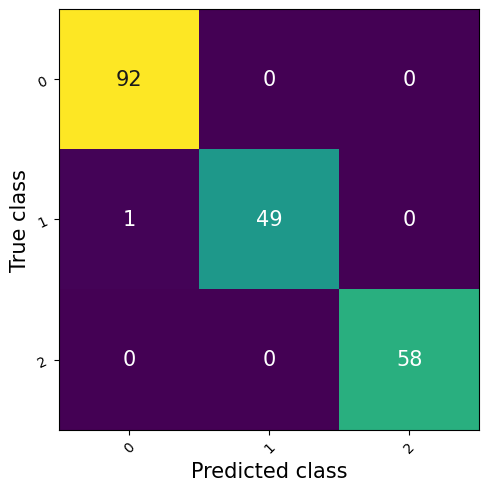

In [32]:
from torchmetrics.utilities.plot import plot_confusion_matrix
plot_confusion_matrix(matrix)

In [33]:
from pathlib import Path

In [34]:
MODEL_PATH = Path("model1")
MODEL_PATH.mkdir(parents=True, exist_ok=True)

MODEL_NAME = "penguen_classification_model.pth"
MODEL_SAVE_PATH = MODEL_PATH / MODEL_NAME

torch.save(obj=model.state_dict(), f=MODEL_SAVE_PATH)

In [35]:
loaded_model = PenguenClasification()

In [36]:
loaded_model.load_state_dict(torch.load(MODEL_SAVE_PATH))

<All keys matched successfully>

In [37]:
new_sample = np.array([[39.1,18.7,181,3750,0,0,1,1,0]])
new_sample_tensor = torch.tensor(new_sample, dtype = torch.float32)
loaded_model.eval()
with torch.inference_mode():
    logit = loaded_model(new_sample_tensor)
    probs = torch.softmax(logit, dim = 1)
    predicted_class = torch.argmax(probs, dim=1).item()
le.inverse_transform([predicted_class])[0]

'Gentoo'

In [38]:
print(MODEL_SAVE_PATH.resolve())

/content/model1/penguen_classification_model.pth


In [39]:
from google.colab import files

files.download(str(MODEL_SAVE_PATH))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [40]:
import joblib

joblib.dump(scaler, "scaler.pkl")

['scaler.pkl']

In [41]:
from google.colab import files

files.download("scaler.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>